# Gradient Boosting: implementación y evaluación temporal

## 1. Objetivo y alcance

Este notebook documenta el candidato adicional de Fase 3. Lee evidencia de una corrida real y se ejecuta desde cero sin entrenamiento ni nuevas propuestas de Optuna. La selección del trial usa exclusivamente entrenamiento. La evaluación de test y la selección del ganador global pertenecen al cierre conjunto.

In [1]:
import sys, json
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown, Image
raiz = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(raiz / "src"))
from auxiliar_functions import tabla_simple
salida = raiz / "results/gradient_boosting"
leer = lambda nombre: json.loads((salida / nombre).read_text(encoding="utf-8"))
resumen, evaluacion = leer("resumen.json"), leer("validacion.json")
detalle, verificacion = leer("detalle.json"), leer("verificacion.json")
contrato = detalle["configuracion"]["configuracion"]
print("Tabla 1. Identificación y estados del estudio")
display(tabla_simple(pd.DataFrame([{"estudio": resumen["estudio"], "trials": resumen["total"], **resumen["estados"]}])))

Tabla 1. Identificación y estados del estudio


,estudio,trials,COMPLETE,PRUNED
0,gradient_boosting-temporal-v1,100,38,62


## 2. Datos, pipeline y validación

Se usa exclusivamente el CSV existente y las quince variables del linaje, en el orden oficial. Cada fold crea un pipeline A nuevo; su imputador aprende medianas del ajuste y StandardScaler aprende de esos mismos datos imputados. Se reemplaza Ridge por GradientBoostingRegressor sin modificar Fase 2. Por ejemplo, para valores de ajuste 1, vacío y 5, la mediana es 3; una fila futura con valor 100 no cambia esa mediana. El objetivo permanece en kW. Los cinco pliegues conservan gap=1 y evalúan solo filas comunes a los baselines.

In [2]:
print("Tabla 2. Variables de entrada en el orden oficial")
display(tabla_simple(pd.DataFrame({"orden": range(1, len(contrato["predictoras"])+1), "variable": contrato["predictoras"]})))
print("Tabla 3. Contrato de optimización")
display(tabla_simple(pd.DataFrame([{k: contrato[k] for k in ["sampler", "pliegues", "gap", "metrica", "max_trials", "python"]}])))

Tabla 2. Variables de entrada en el orden oficial


,orden,variable
0,1,Frio (Kw)
1,2,Frio (Kw) x frio_hace_2_dias
2,3,frio_media_7_dias
3,4,Sala Maq (Kw)
4,5,Frio (Kw) x Consolidado Agua | Agua Planta (Hl)
5,6,Servicios (Kw)
6,7,Frio (Kw) x Totalizadores Energia | KW Trafo 9
7,8,dia_anio_coseno
8,9,frio_hace_2_dias x Consolidado Agua | Agua Planta (Hl)
9,10,dia_anio_coseno x Consolidado Agua | Agua Planta (Hl)


Tabla 3. Contrato de optimización


,sampler,pliegues,gap,metrica,max_trials,python
0,TPESampler(seed=42),5,1,mae,100,3.12.14


## 3. Espacio y decisión experimental

Se mantiene el sampler, la semilla y el podador verificados en los ejecutores de XGBoost y LightGBM. Se propone alpha solamente para huber. Se conserva la estandarización porque forma parte del contrato solicitado; para árboles no es una exigencia matemática. La alternativa de imputar antes de dividir se descarta porque incorporaría información futura. La pérdida absoluta ofrece resistencia a extremos y squared_error penaliza más los errores grandes; huber combina ambos criterios. El estudio mide cuál configuración logra menor MAE conjunto, sin interpretar la elección como evidencia causal.

In [3]:
print("Tabla 4. Espacio de búsqueda")
display(tabla_simple(pd.DataFrame([{"parametro": k, **v} for k, v in contrato["espacio"].items()]).fillna("")))
print("Tabla 5. Configuración elegida y parámetros fijos")
display(tabla_simple(pd.DataFrame([{"parametro": k, "valor": str(v)} for k, v in evaluacion["parametros"].items()])))
print("Tabla 6. Métricas del mejor trial por fold")
ganador = next(t for t in detalle["trials"] if t["trial"] == evaluacion["trial"])
display(tabla_simple(pd.DataFrame(ganador["pliegues"])))

Tabla 4. Espacio de búsqueda


,parametro,tipo,low,high,step,log,choices
0,n_estimators,int,100.00,600.00,50.00,,
1,learning_rate,float,0.01,0.15,,True,
2,max_depth,int,2.00,4.00,,,
3,min_samples_leaf,int,3.00,20.00,,,
4,subsample,float,0.60,1.00,0.10,,
5,max_features,float,0.60,1.00,0.10,,
6,loss,categorical,,,,,"['squared_error', 'absolute_error', 'huber']"
7,alpha,float,0.75,0.95,0.05,,


Tabla 5. Configuración elegida y parámetros fijos


,parametro,valor
0,random_state,42
1,n_iter_no_change,None
2,n_estimators,550
3,learning_rate,0.01592324888670594
4,max_depth,2
5,min_samples_leaf,4
6,subsample,0.8
7,max_features,0.8
8,loss,absolute_error


Tabla 6. Métricas del mejor trial por fold


,inicio_utc,fin_utc,duracion_segundos,paso,filas_ajuste,filas_comunes,ultimo_indice_ajuste,primer_indice_evaluacion,mae,rmse,r2,mae_acumulado
0,2026-11-15T04:14:28.047925+00:00,2026-11-15T04:14:29.017195+00:00,0.97,0,139,138,138,140,5938.42,7099.52,-0.26,5938.42
1,2026-11-15T04:14:29.086440+00:00,2026-11-15T04:14:30.050734+00:00,0.96,1,277,131,276,278,3515.65,4493.22,-0.08,4758.56
2,2026-11-15T04:14:30.125353+00:00,2026-11-15T04:14:31.084628+00:00,0.96,2,415,137,414,416,3115.96,3954.97,0.76,4204.28
3,2026-11-15T04:14:31.103196+00:00,2026-11-15T04:14:32.334607+00:00,1.23,3,553,134,552,554,2811.73,3463.59,0.73,3858.72
4,2026-11-15T04:14:32.367247+00:00,2026-11-15T04:14:33.707258+00:00,1.34,4,691,137,690,692,3369.08,4502.77,0.49,3759.64


## 4. Resultados comparables

El candidato se ajustó con todas las filas de entrenamiento después de terminar el estudio. Las métricas de validación se calculan sobre las mismas observaciones que ambos baselines y los cuatro resultados archivados de XGBoost y LightGBM. El diagnóstico comprueba igualdad de índices, fechas y objetivos, además de la cantidad. El error dentro de entrenamiento sirve como diagnóstico y no reemplaza las predicciones fuera de muestra.

In [4]:
print("Tabla 7. Comparación sobre la misma validación independiente")
display(tabla_simple(pd.read_csv(salida / "comparacion_validacion.csv")))
print("Tabla 8. Métricas dentro de entrenamiento")
display(tabla_simple(pd.read_csv(salida / "metricas_entrenamiento.csv")))
print("Tabla 9. Resumen de residuos")
display(tabla_simple(pd.read_csv(salida / "resumen_residuos.csv")))

Tabla 7. Comparación sobre la misma validación independiente


,modelo,mae,rmse,r2,filas
0,Gradient Boosting,2316.31,2948.04,0.42,171
1,XGBoost inicial,2221.76,2844.31,0.46,171
2,XGBoost refinado,2229.22,2853.13,0.46,171
3,LightGBM inicial,2321.04,2937.76,0.43,171
4,LightGBM segunda,2276.74,2873.14,0.45,171
5,persistencia,2668.33,3319.43,0.27,171
6,media_movil,2497.65,3368.08,0.25,171


Tabla 8. Métricas dentro de entrenamiento


,mae,rmse,r2
0,2402.31,3255.52,0.83


Tabla 9. Resumen de residuos


,mae,rmse,r2,filas,sesgo_real_menos_predicho,mediana_residuo,desvio_residuo,p05_residuo,p95_residuo,p95_error_absoluto,max_error_absoluto,subestimaciones,sobreestimaciones,fraccion_error_top10
0,2316.31,2948.04,0.42,171,13.61,-161.41,2956.67,-4876.10,5074.72,6070.09,8748.57,79,92,0.17


## 5. Diagnóstico gráfico y errores extremos

Los residuos son real menos predicho; un signo positivo indica subestimación. Los cinco diagnósticos permiten examinar sesgo, dispersión y estructura temporal. Se conserva el estilo de los otros modelos. Se agregan los diez errores más grandes, el historial y la importancia de las quince variables del estimador, con un propósito diferente para cada figura. No se eliminan errores extremos ni se asume normalidad o independencia.

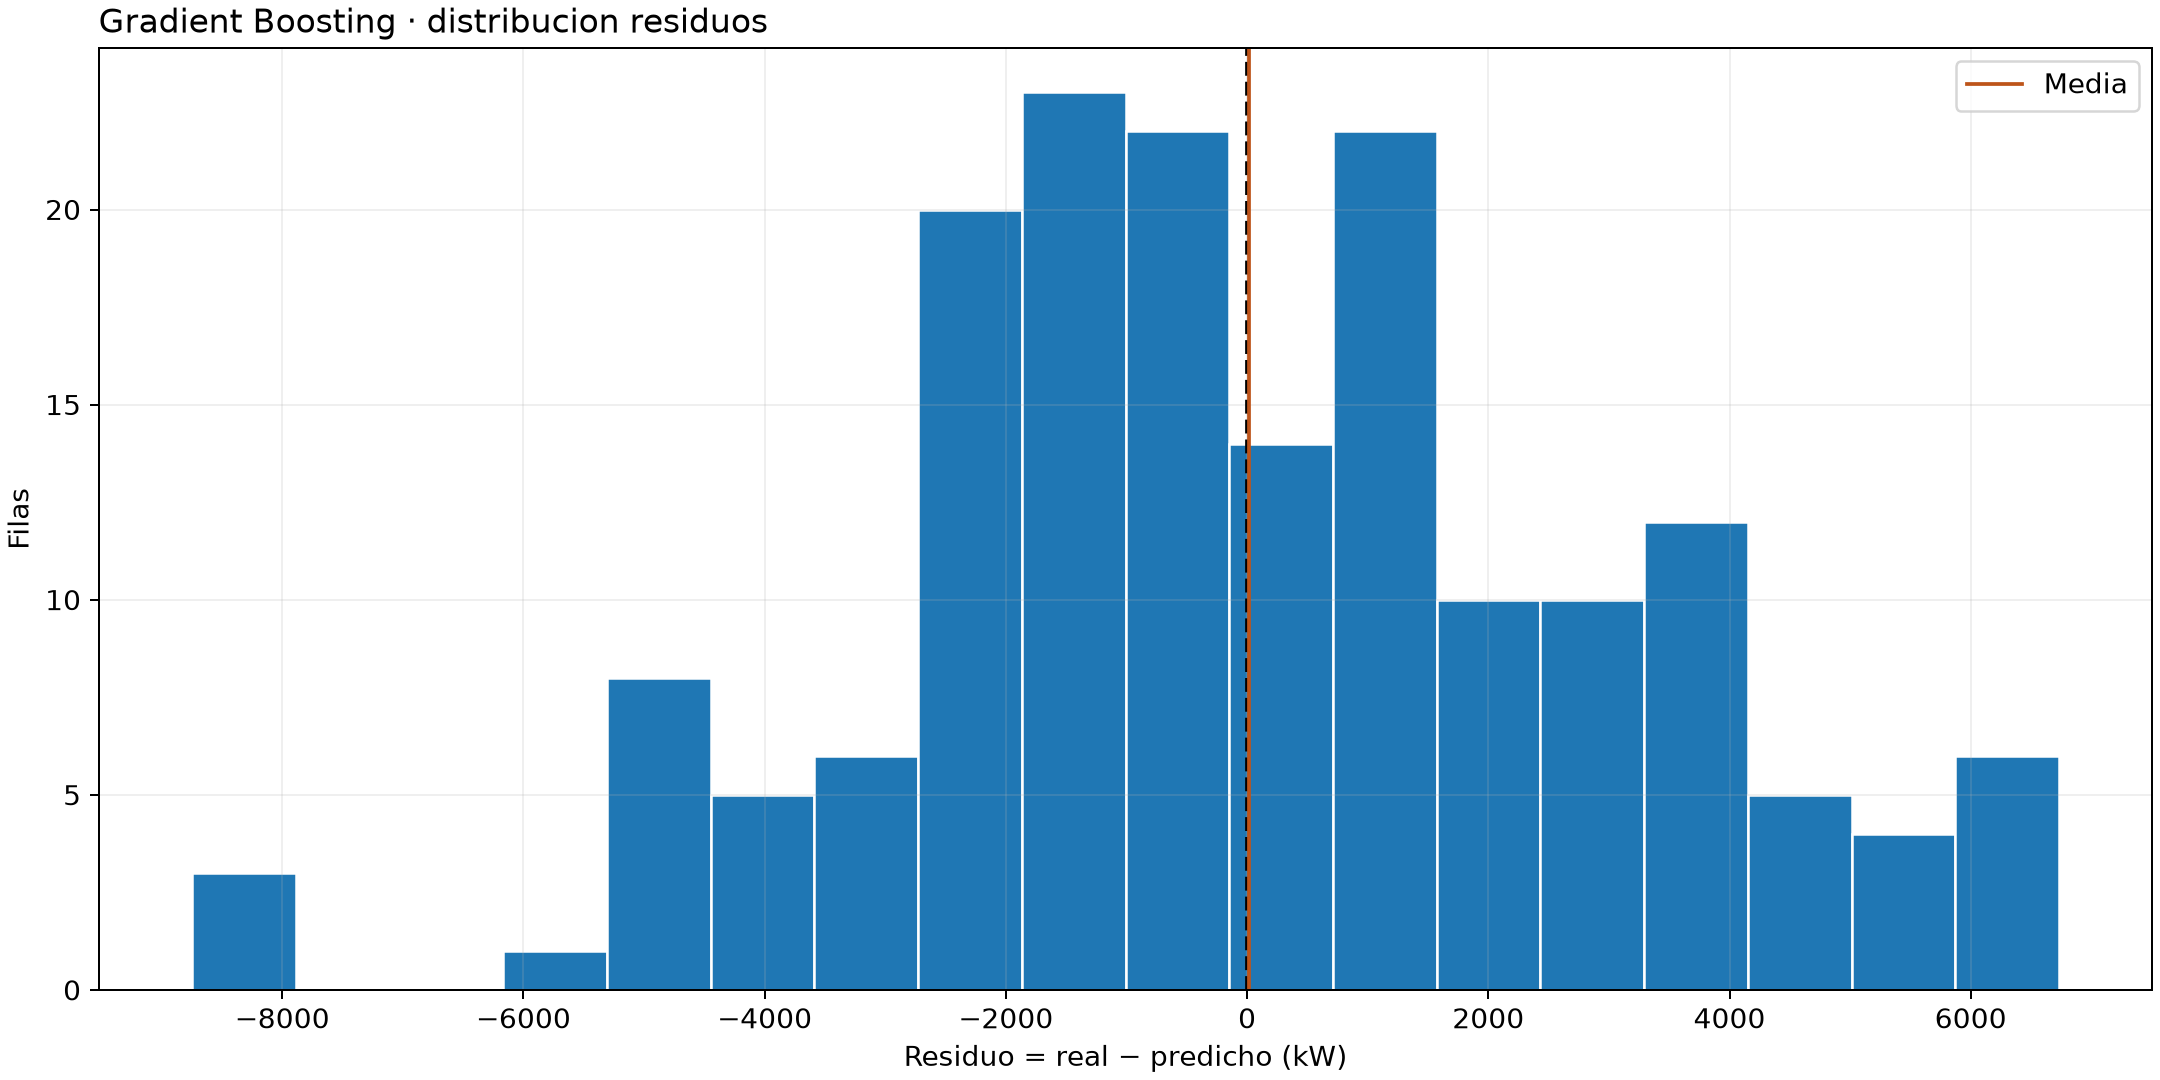

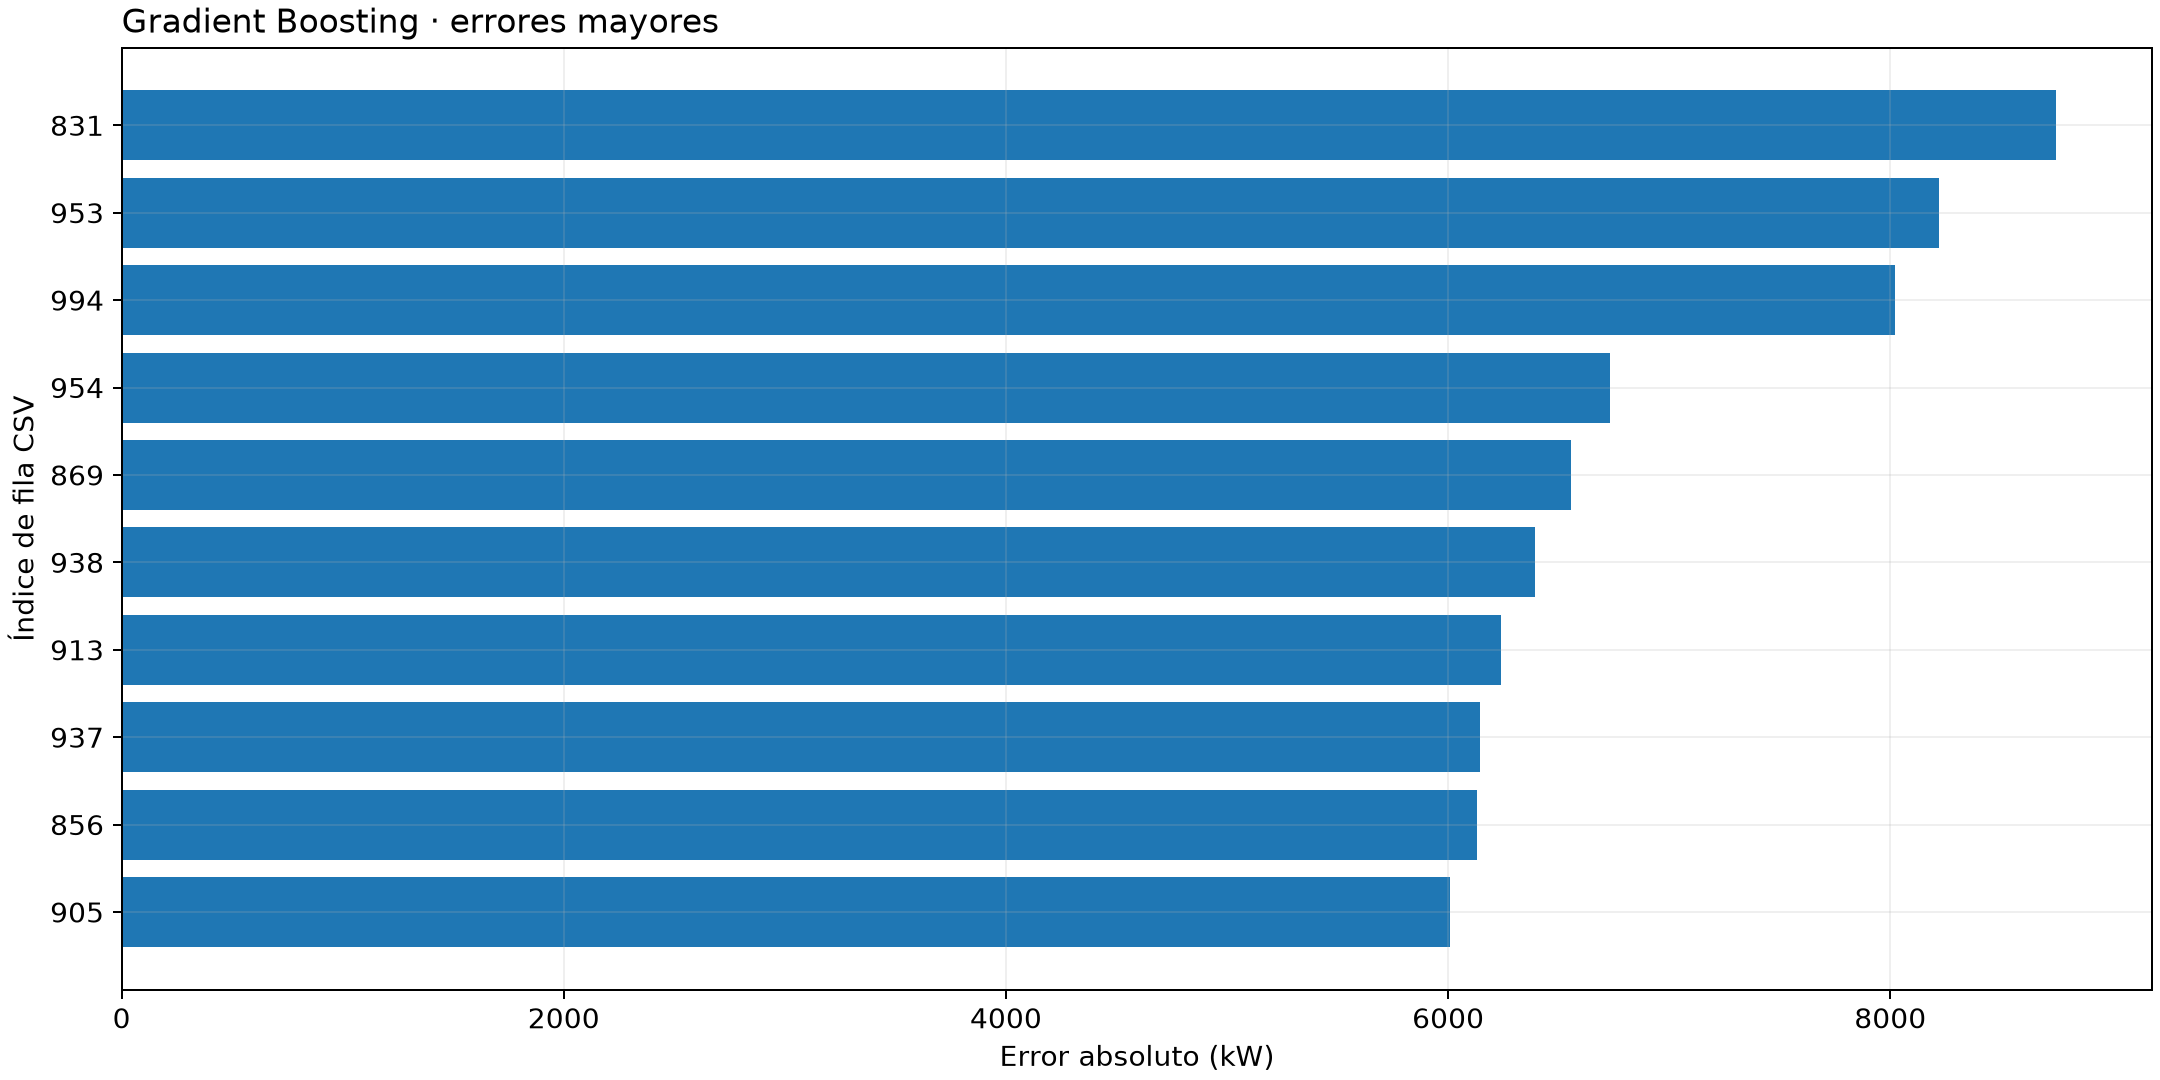

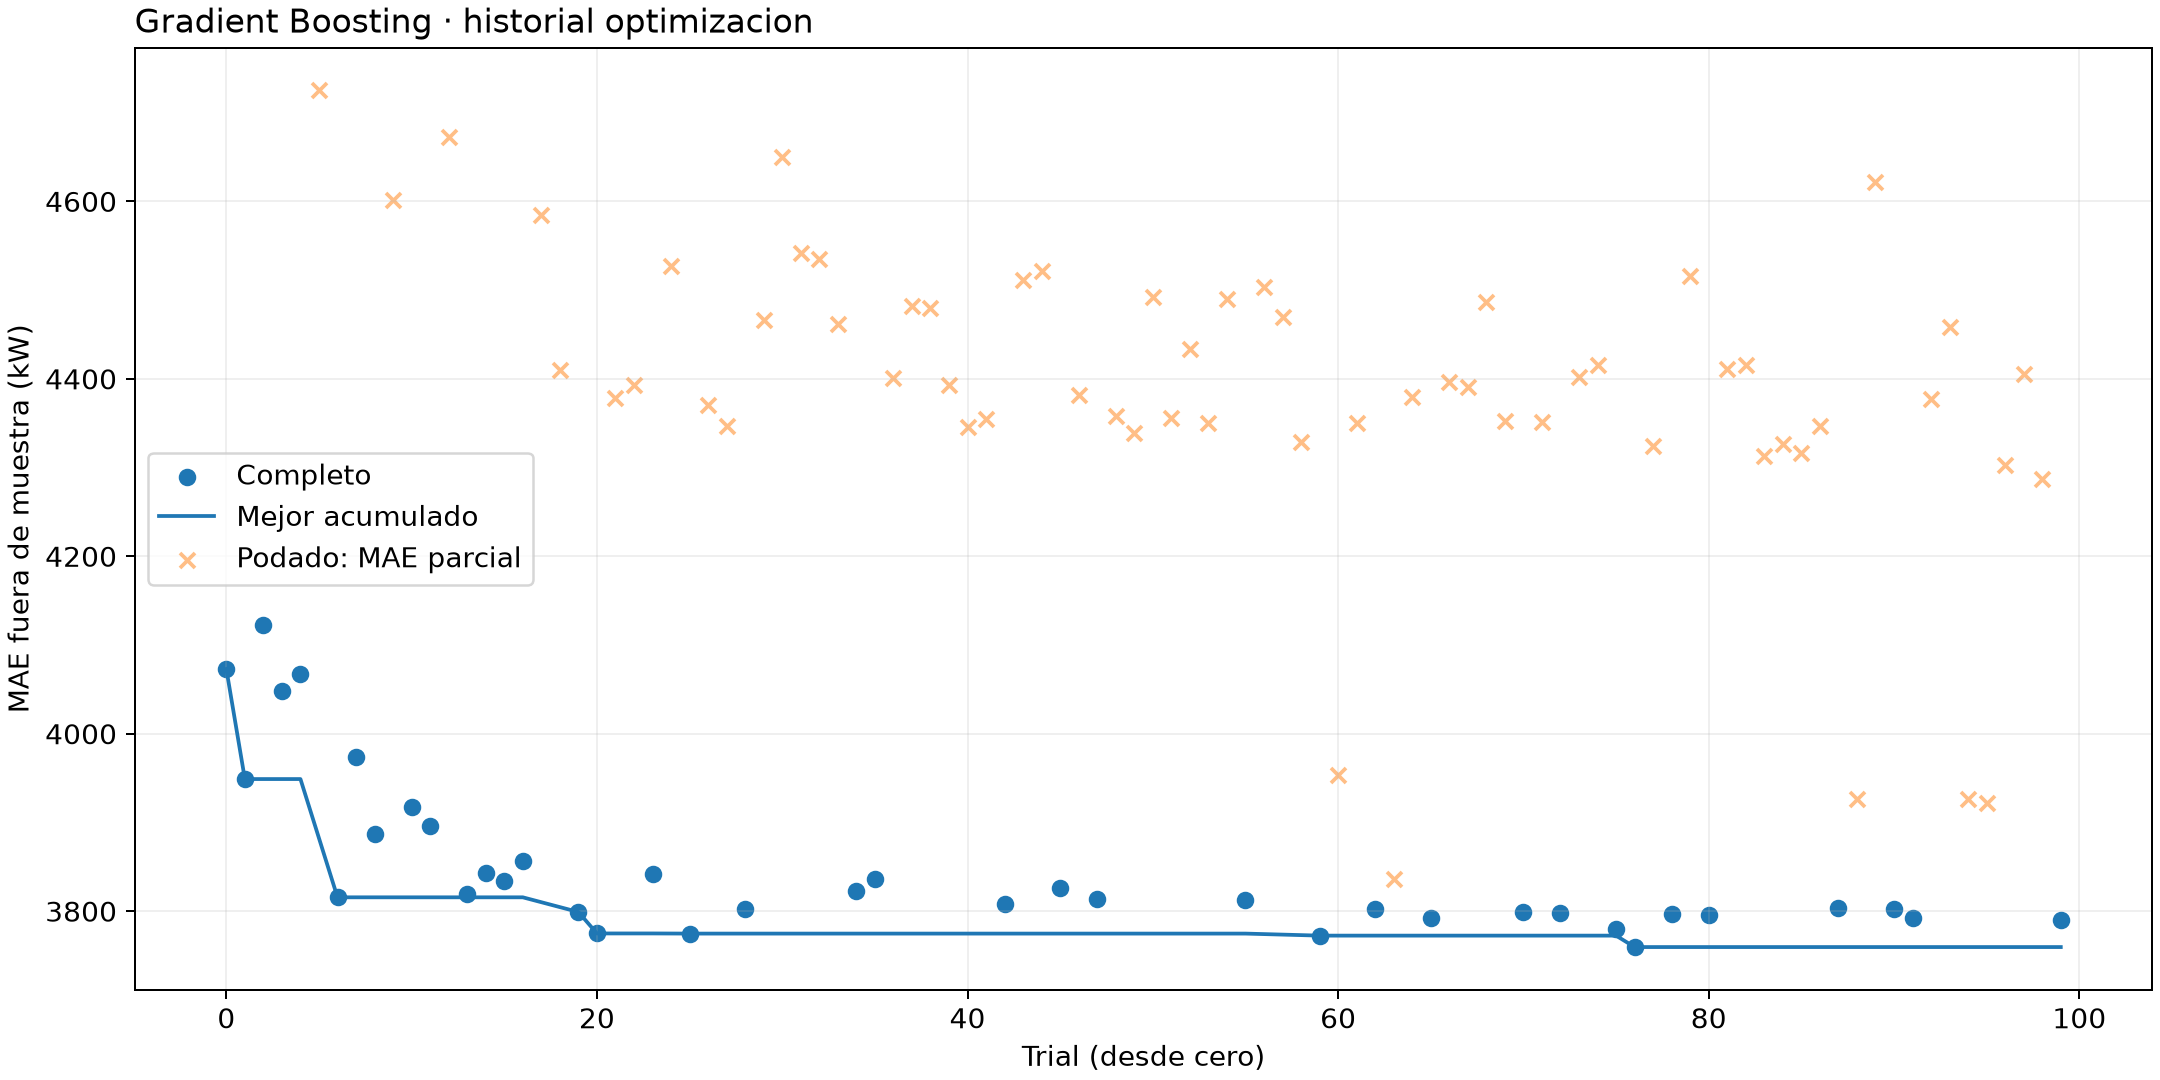

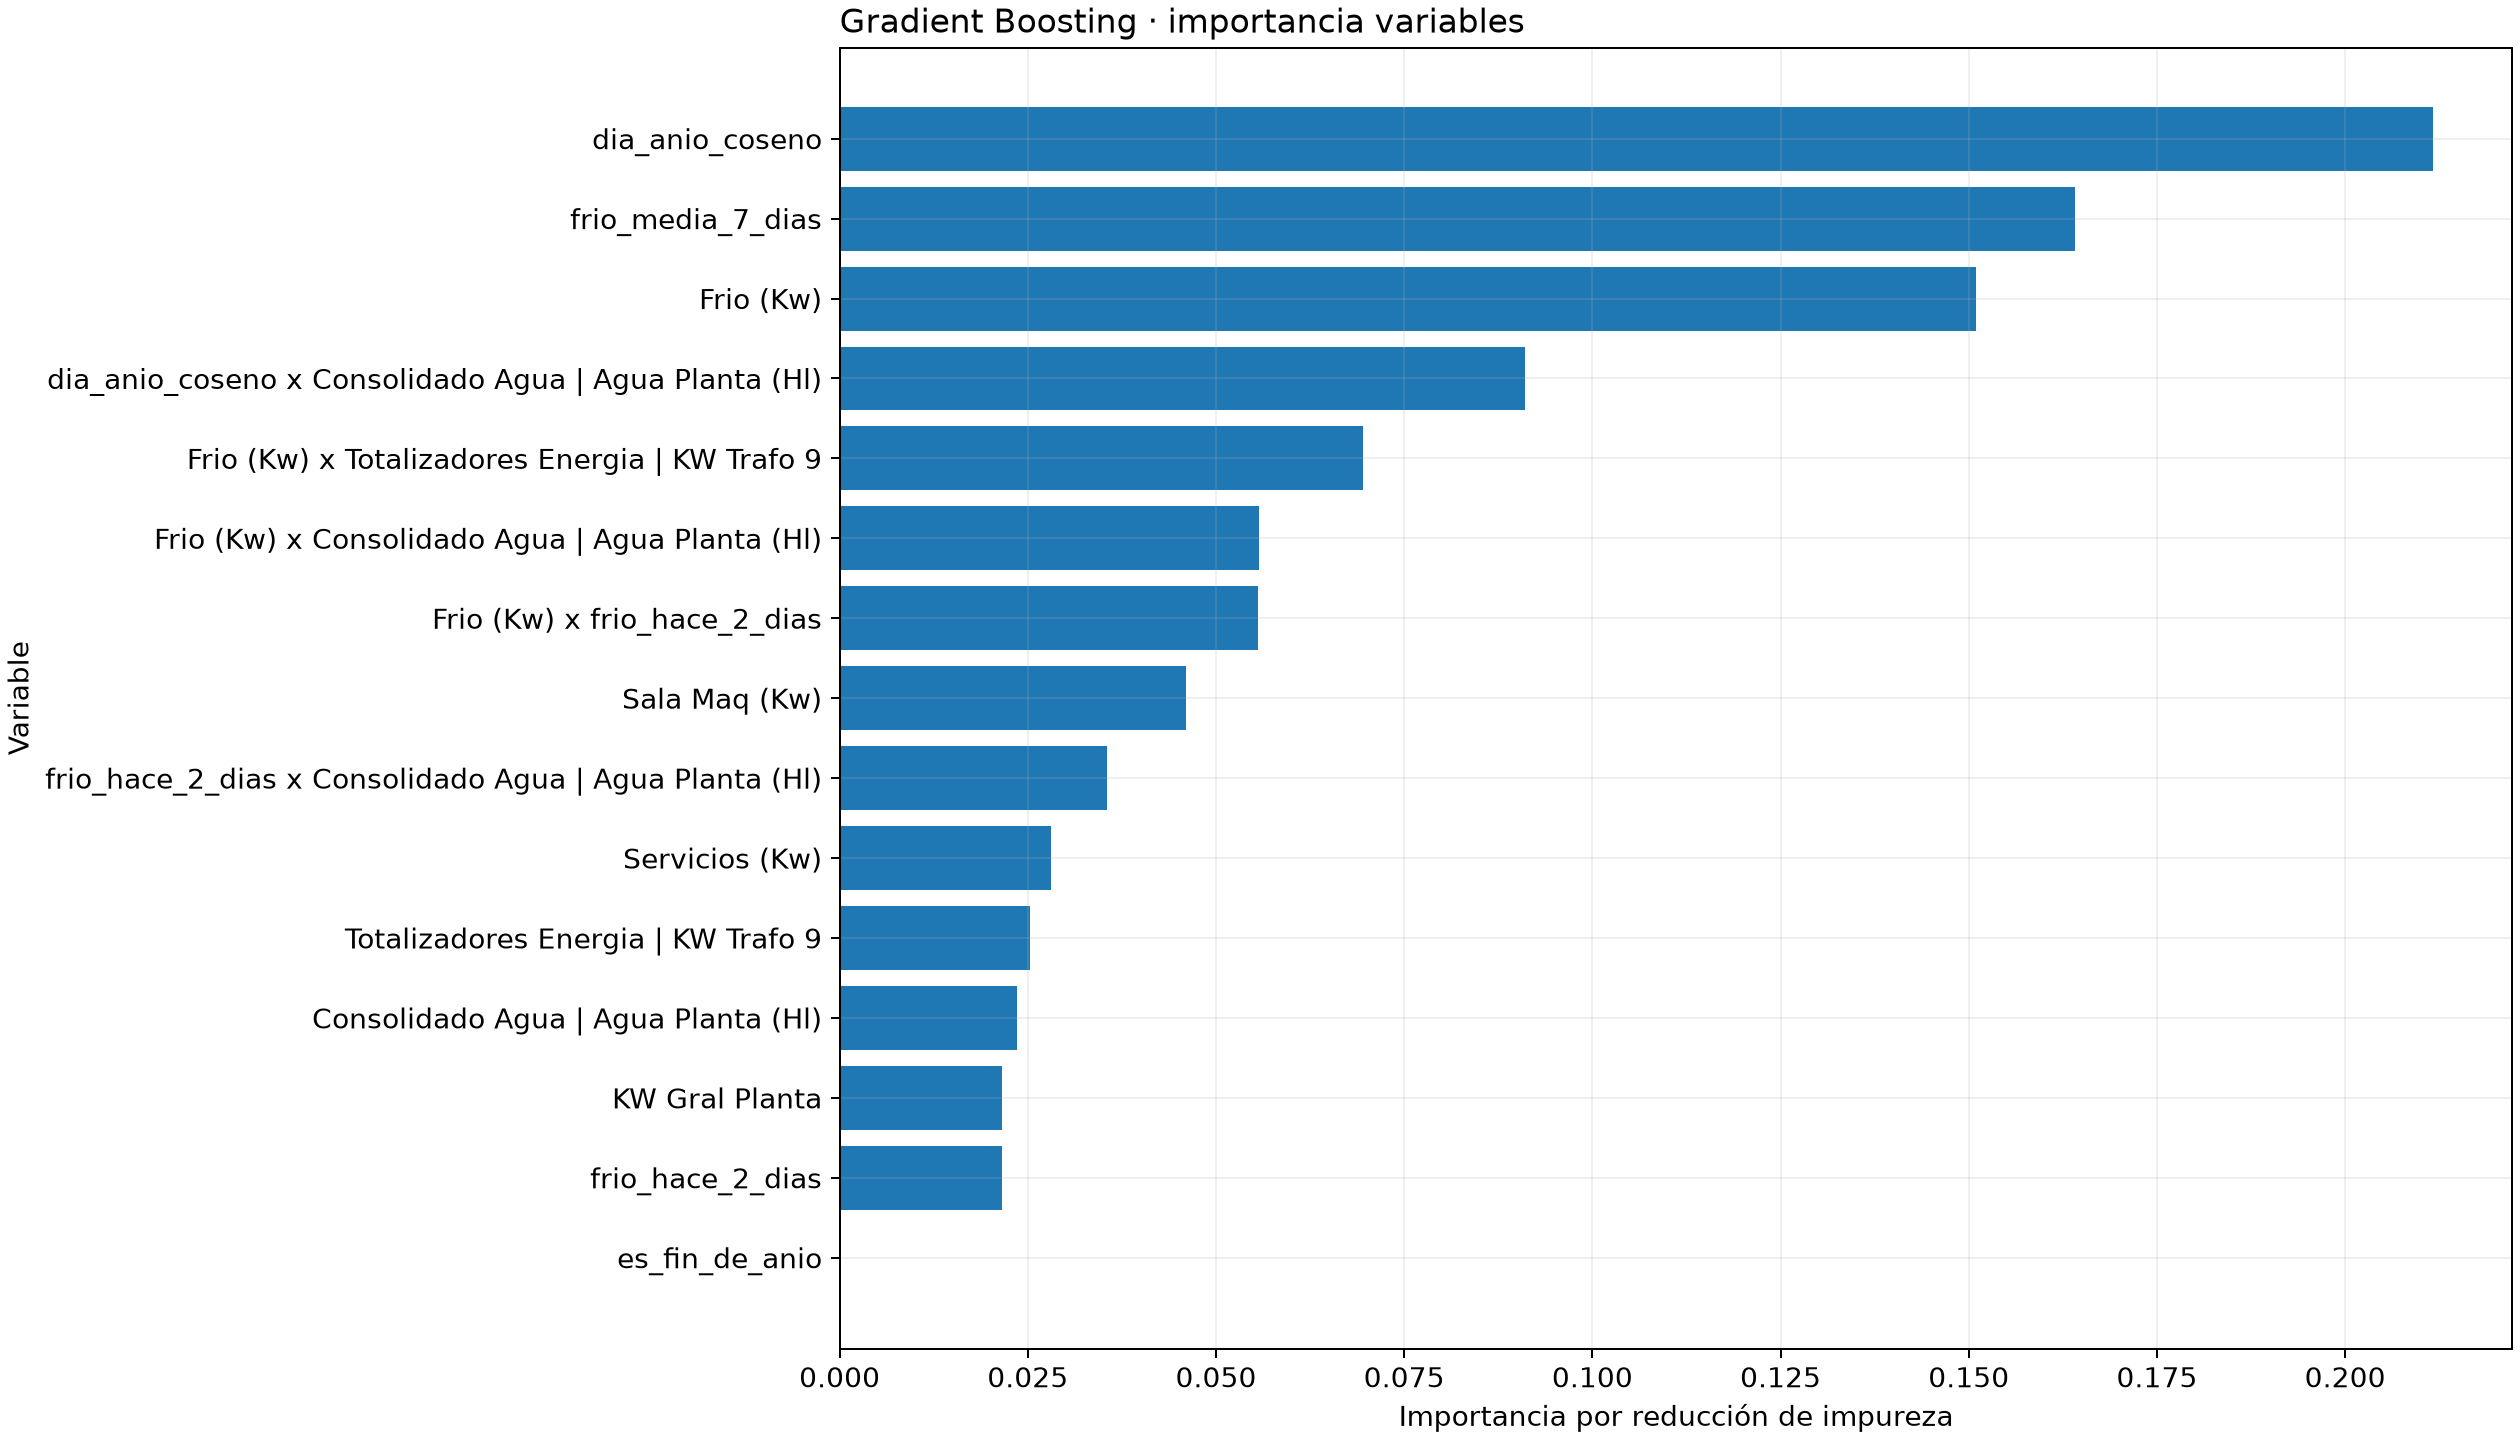

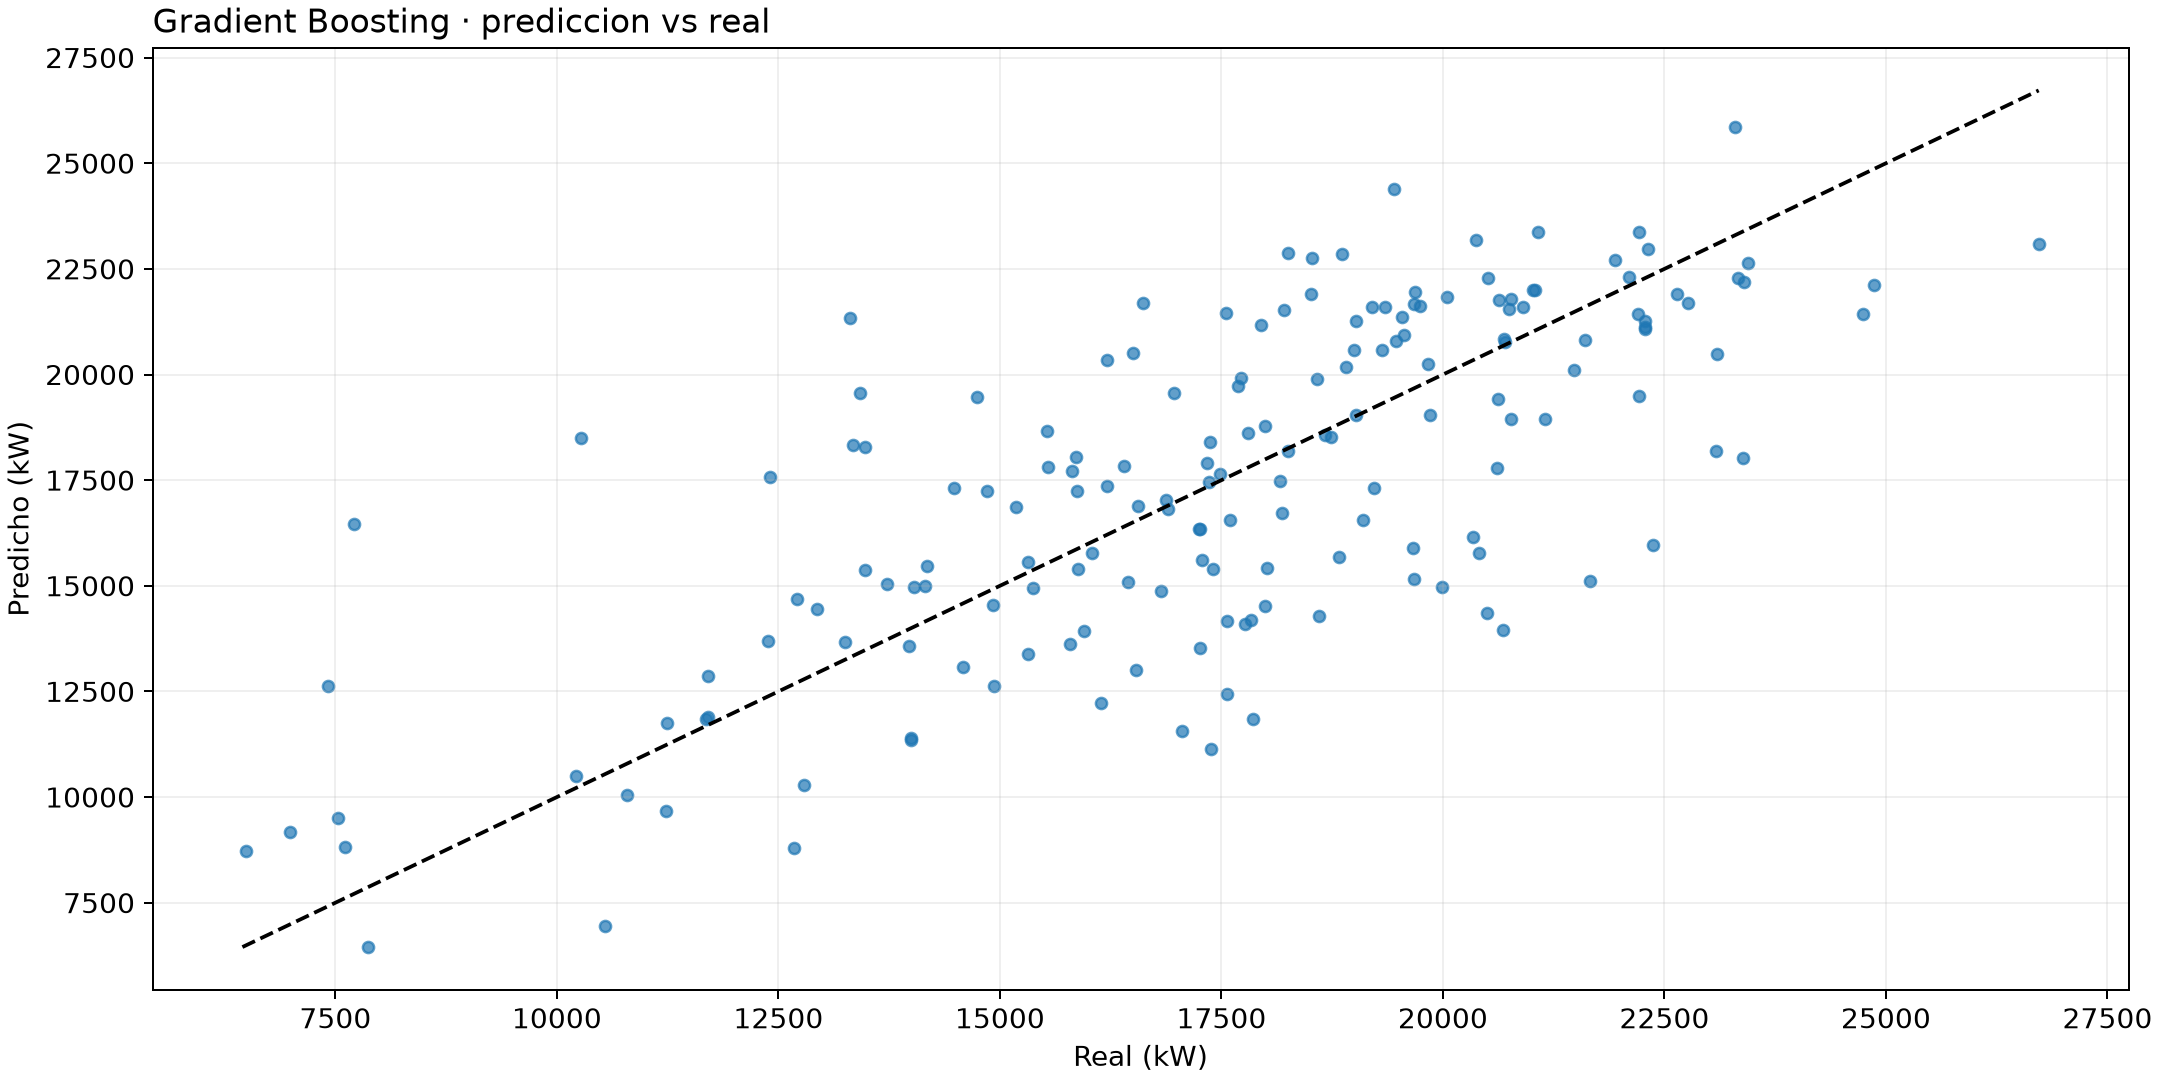

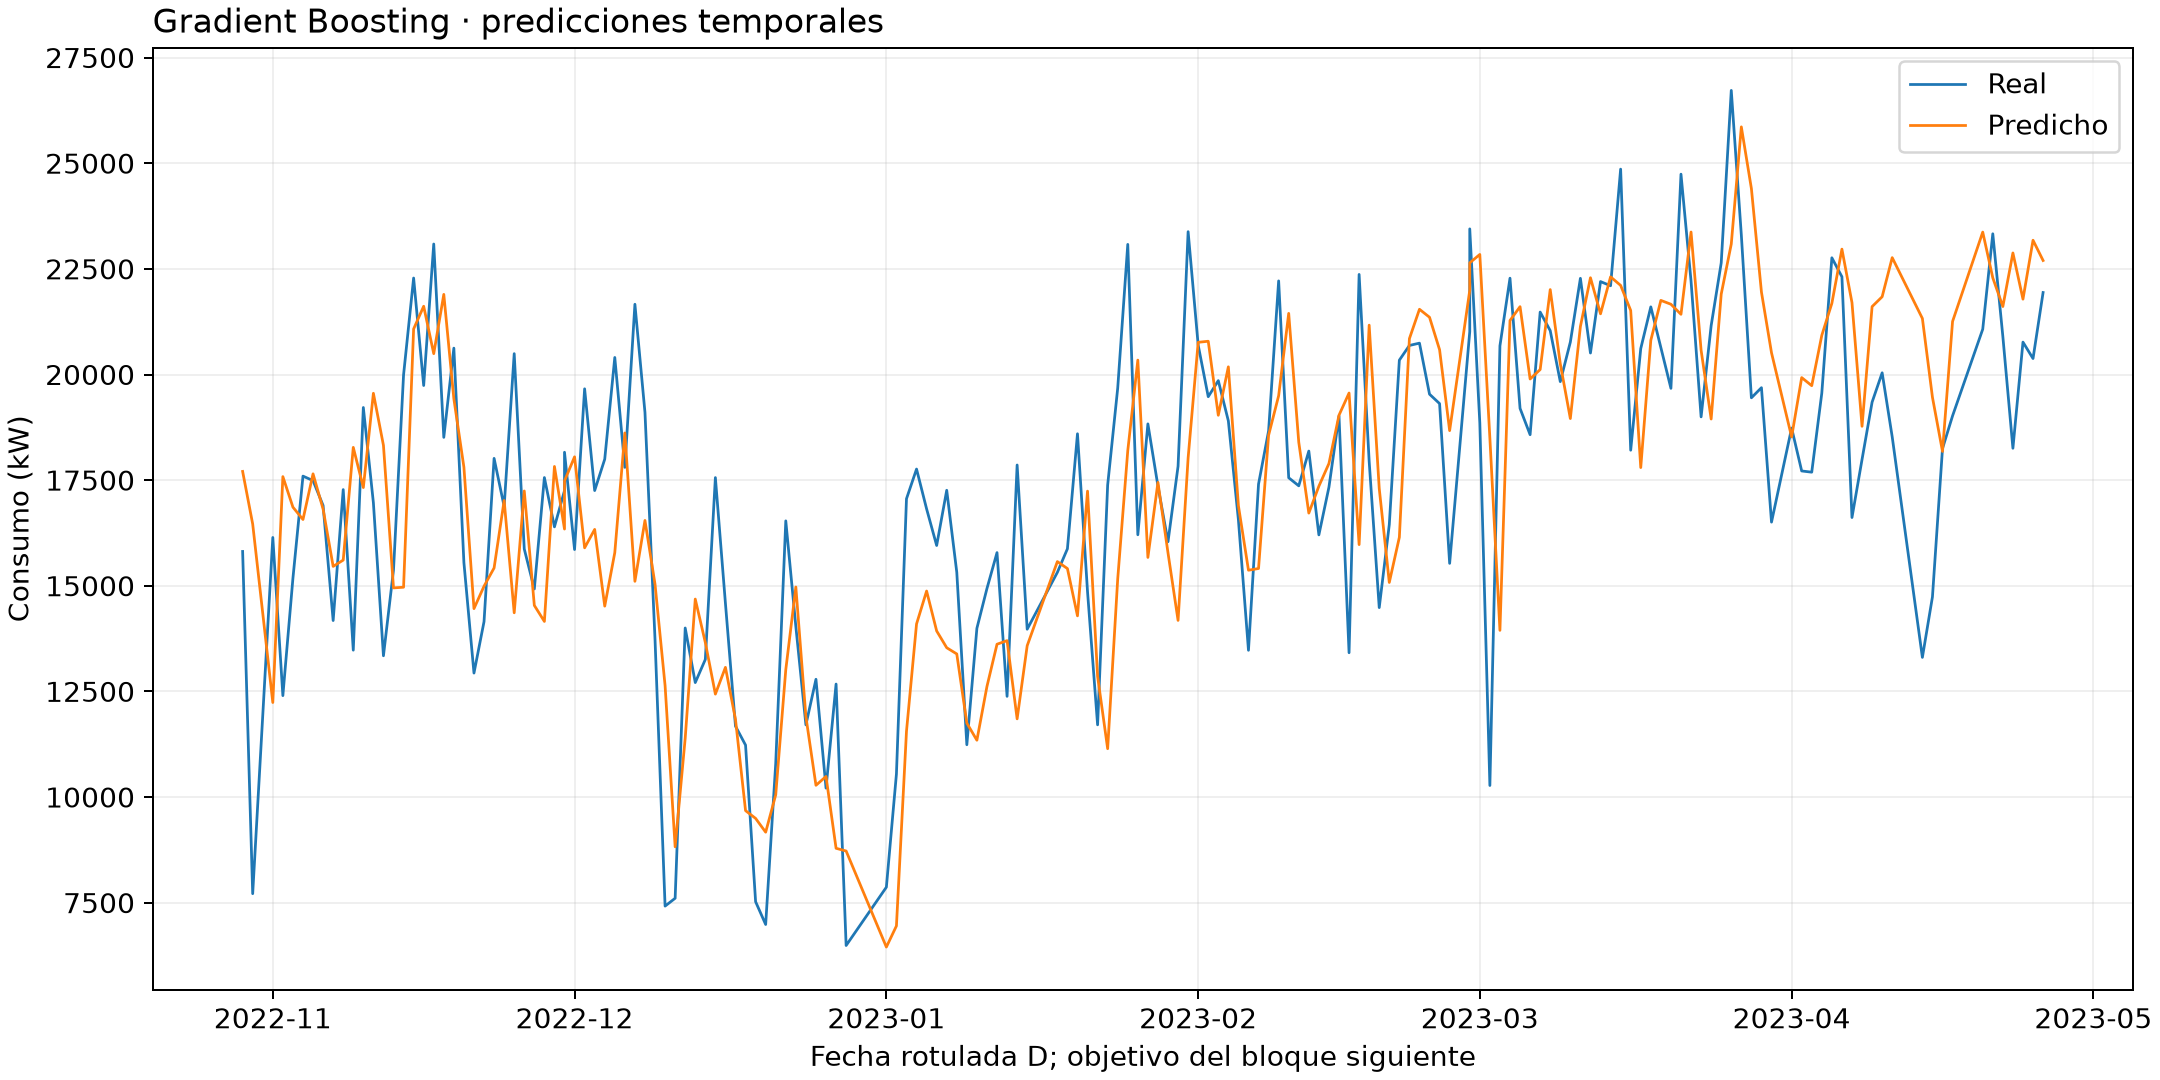

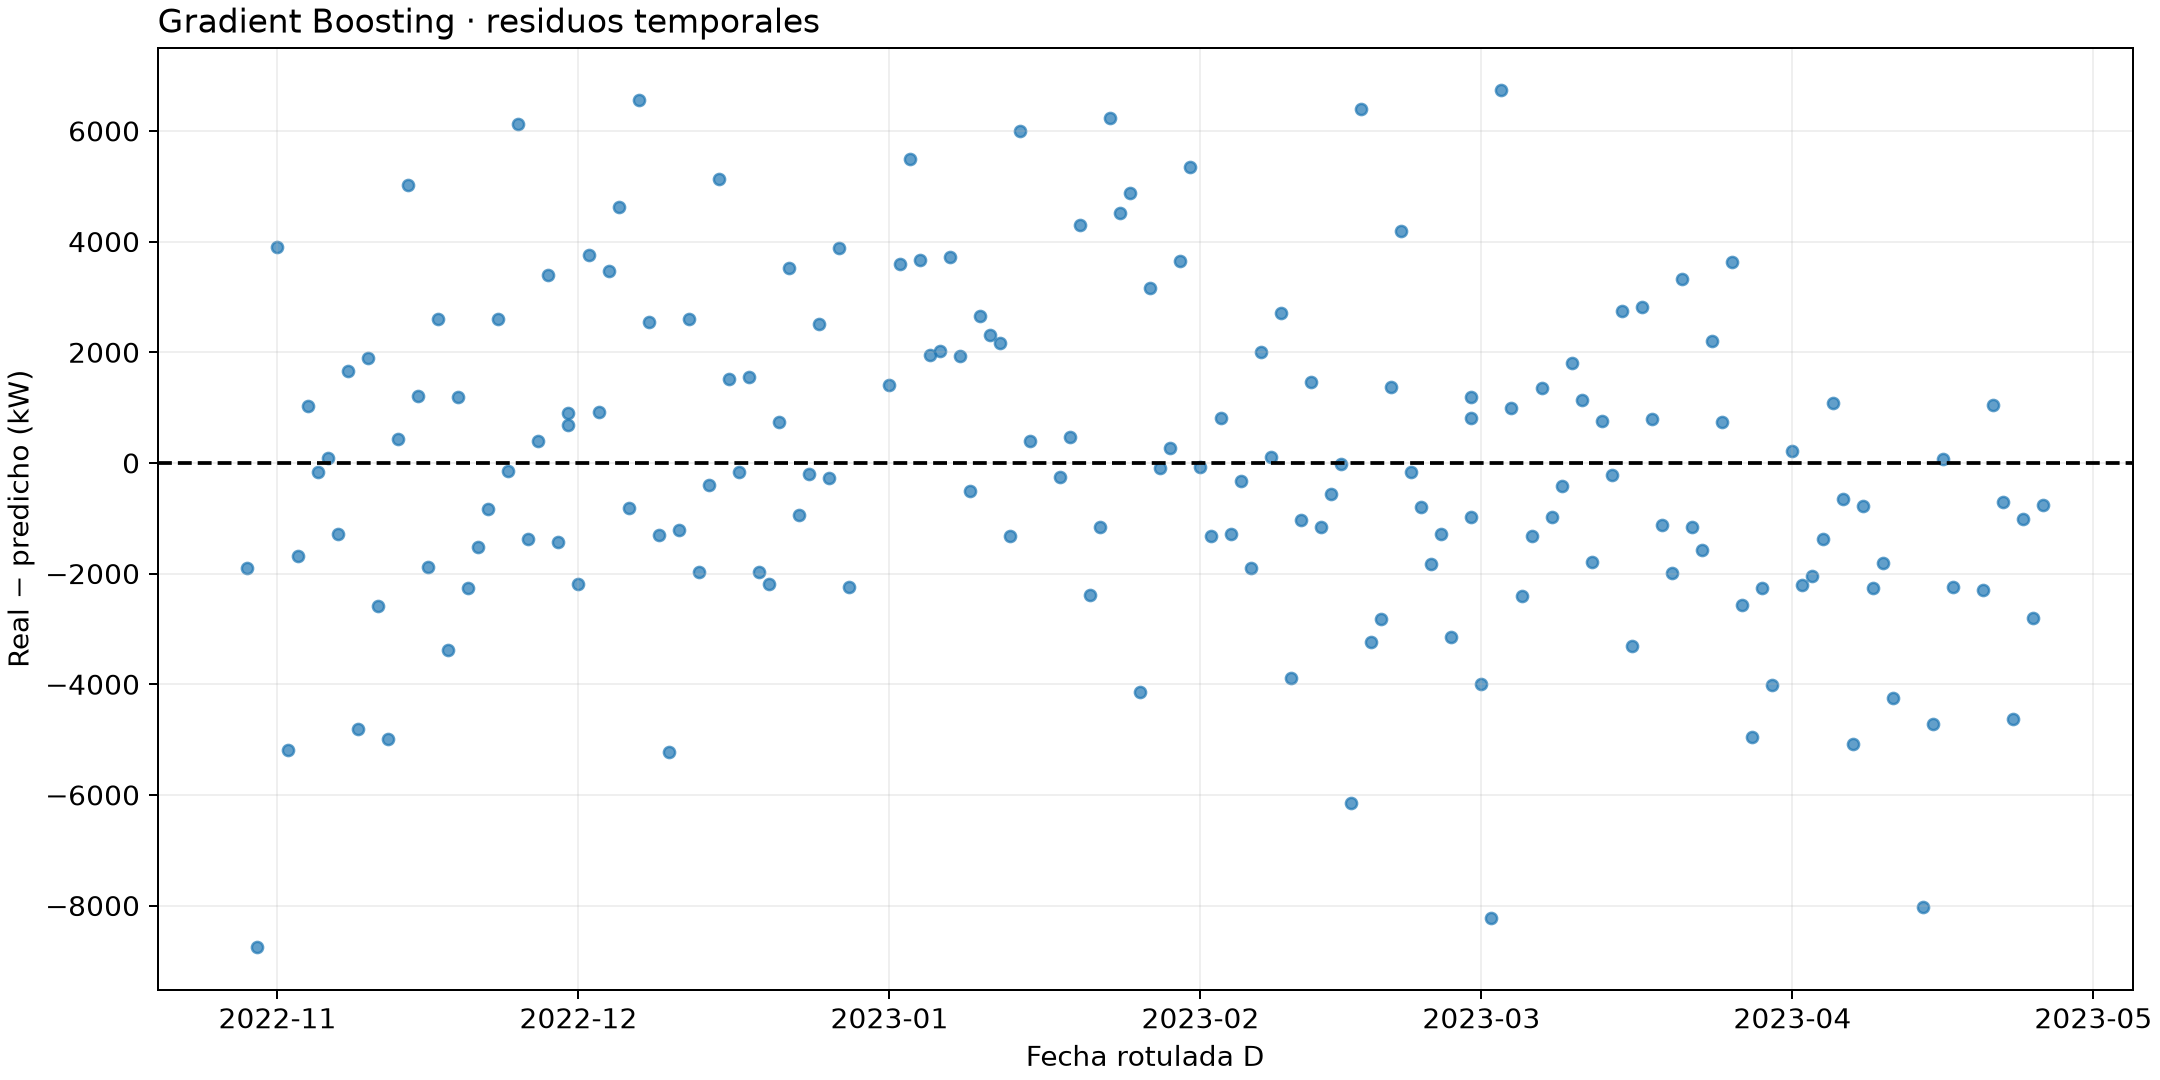

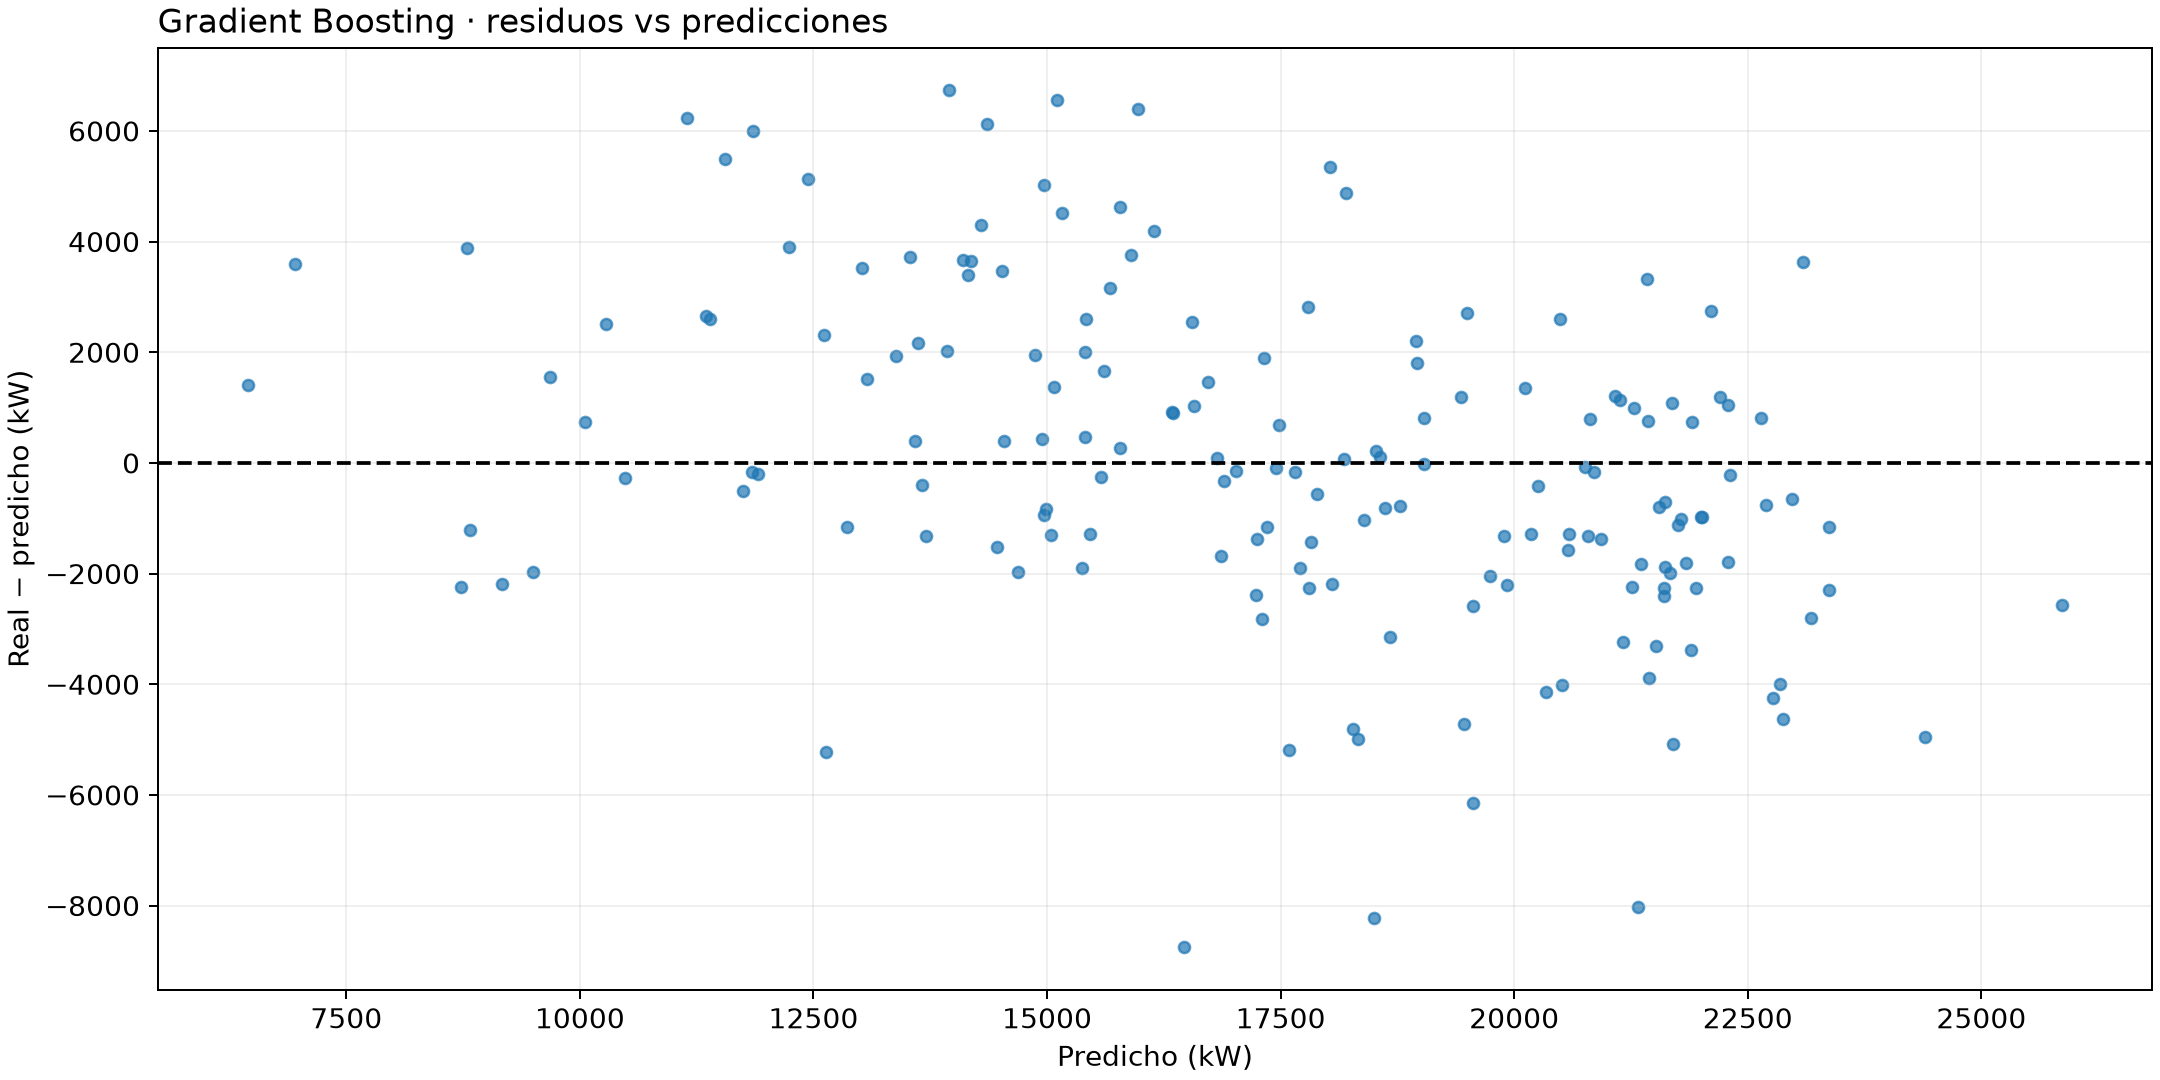

Tabla 10. Errores de mayor magnitud


,indice_csv,DIA,real,predicho,residuo,error_absoluto
0,831,2022-10-30,7714.00,16462.57,-8748.57,8748.57
1,953,2023-03-02,10274.00,18494.43,-8220.43,8220.43
2,994,2023-04-14,13306.00,21327.15,-8021.15,8021.15
3,954,2023-03-03,20679.00,13945.83,6733.17,6733.17
4,869,2022-12-07,21663.00,15106.33,6556.67,6556.67
5,938,2023-02-17,22369.00,15974.74,6394.26,6394.26
6,913,2023-01-23,17384.00,11145.12,6238.88,6238.88
7,937,2023-02-16,13416.00,19562.37,-6146.37,6146.37
8,856,2022-11-25,20494.00,14361.38,6132.62,6132.62
9,905,2023-01-14,17859.00,11851.45,6007.55,6007.55


Tabla 11. Residuos por mes rotulado


,mes,filas,sesgo,mae
0,2022-10,2,-5321.34,5321.34
1,2022-11,31,-11.80,2149.82
2,2022-12,28,794.97,2301.56
3,2023-01,29,2080.86,2759.36
4,2023-02,29,-374.03,1826.82
5,2023-03,30,-439.53,2377.43
6,2023-04,22,-2056.18,2274.36


In [5]:
for ruta in sorted((salida / "graficos").glob("*.png")):
    display(Image(filename=str(ruta)))
print("Tabla 10. Errores de mayor magnitud")
display(tabla_simple(pd.read_csv(salida / "errores_mayores.csv")))
print("Tabla 11. Residuos por mes rotulado")
display(tabla_simple(pd.read_csv(salida / "residuos_por_mes.csv")))

## 6. Trazabilidad, controles y reproducción

El CSV común conserva cada ajuste de fold y el estado de cada trial; los incompletos mantienen vacías sus métricas finales. SQLite, JSON y el progreso conservan tiempos, semilla, parámetros y estados. Los hashes demuestran preservación de las fuentes. El commit identifica el código ejecutado y el flag de Git informa su estado real. Las instrucciones completas para reproducir o restaurar el estudio están en docs/gradient-boosting.md. La importancia por reducción de impureza no equivale a causalidad y puede repartirse entre variables correlacionadas.

In [6]:
print("Tabla 12. Controles de la ejecución")
controles = pd.DataFrame([verificacion["controles"]])
assert controles.to_numpy().all()
display(tabla_simple(controles))
print("Tabla 13. Reproducibilidad")
display(tabla_simple(pd.DataFrame([{"commit": resumen["commit_codigo"], "dataset_sha256": contrato["dataset_sha256"], "codigo_sha256": contrato["codigo_sha256"], "semilla": contrato["fijos"]["random_state"]}])))

Tabla 12. Controles de la ejecución


,100_trials_terminados,mismas_filas_comparacion,originales_intactos,log_previo_preservado,candidato_reproduce_predicciones,tracking_por_ajuste_y_trial,test_no_evaluado
0,True,True,True,True,True,True,True


Tabla 13. Reproducibilidad


,commit,dataset_sha256,codigo_sha256,semilla
0,2e16156fb04078f83518df9d16b7b0507ae2529b,3bda0f26952d01412f5970de0fb5999659c6fb6965c4f28935ed3bc538134dec,571044f0aa91d4d5dcc428a955348370a99bceb628119950ce49806019bfd891,42


## 7. Conclusión

La interpretación siguiente se genera desde las métricas guardadas, sin cifras copiadas manualmente. Explica sesgos, patrones mensuales, concentración de errores, límites del diagnóstico de sobreajuste y requisitos que dependen de la selección global.

In [7]:
display(Markdown((salida / "informe.md").read_text(encoding="utf-8")))

# Gradient Boosting: estudio y validación del candidato

El estudio gradient_boosting-temporal-v1 finalizó con 100 trials. Ganó el trial 76, por MAE conjunto fuera de muestra 3759.637254 kW. Sus parámetros se guardan en validacion.json; la validación independiente no intervino en su selección.

La validación contiene 171 observaciones idénticas por índice, fecha y objetivo a las cuatro referencias XGBoost y LightGBM. El MAE es 2316.309953, RMSE 2948.038902 y R² 0.424633. La mejora relativa frente al mejor baseline es 7.26 %. Comparación completa en comparacion_validacion.csv.

El residuo se define como real menos predicho. El sesgo medio es 13.61 kW; valores positivos indican subestimación. El percentil 95 del error absoluto es 6070.09 y el máximo 8748.57 kW. Los diez mayores errores concentran 17.47 % del error absoluto. No se eliminan observaciones extremas.

El mes con mayor MAE es 2022-10: 5321.34 kW en 2 filas, sesgo -5321.34 kW. residuos_por_mes.csv y los gráficos temporales muestran heterogeneidad: un promedio global no representa todos los meses. Las fechas rotuladas pueden repetirse y estar desfasadas; el índice CSV es la identidad, conforme al ADR 0002. No se infiere causalidad ni independencia de los residuos.

Entre los meses con al menos veinte observaciones, el mayor sesgo positivo aparece en 2023-01: 2080.86 kW en 29 filas; el menor aparece en 2023-04: -2056.18 kW en 22 filas. Estos cambios de signo muestran por qué el sesgo global cercano a cero puede ocultar patrones temporales. Octubre contiene solo dos filas y no permite una conclusión mensual estable.

El MAE dentro de entrenamiento es 2402.31 kW en 813 filas comunes. La brecha validación menos entrenamiento es -86.00 kW. Es un diagnóstico de sobreajuste limitado por el cambio de período y tamaño de muestra. El MAE CV usa períodos anteriores y ajustes menores; no es directamente comparable con el error de validación. No se asegura ausencia de sobreajuste ni significación estadística de diferencias pequeñas.

La importancia de las 15 variables proviene del estimador ajustado (reducción de impureza), no de Optuna. Es descriptiva, puede repartirse entre variables correlacionadas y no demuestra causalidad. Se conserva mediana y StandardScaler mediante la variante A; se aprende de nuevo dentro de cada fold. No se transforma el objetivo.

El tracking común conserva cada fold ajustado y cada trial con su estado. Los trials PRUNED/FAIL tienen métricas finales vacías; los folds completos conservan métricas parciales identificadas. detalle.json conserva inicios, finales, duraciones y métricas por fold; SQLite y progreso.jsonl permiten auditar la secuencia. Los timestamps de fold usan UTC; los de Optuna y del registrador común conservan el reloj local real. No se alteran fechas históricas.

La sección 3.1 incorpora un candidato adicional: Gradient Boosting no reemplaza los cuatro modelos obligatorios, y su cumplimiento conjunto exige también Random Forest y Ridge/Lasso. Se completa 3.2 para este estudio y 3.3 para este candidato. En 3.4 solo se guarda el candidato entrenado con train; selección global, entrenamiento con train+validation, evaluación final de test, versión semántica y registry quedan pendientes del cierre conjunto. No se modifican train_model.py ni el notebook compartido.

Persisten las limitaciones heredadas: selección previa de variables no anidada, consultas anteriores de validación y disponibilidad operacional de ciertas mediciones pendiente de certificar (ADR 0017). La evaluación es histórica, no una garantía del test oculto.
